# 03 - Temperature-Dependent Properties & Plotting

A constant heat capacity is a fine approximation over a narrow temperature
window, but combustion, gas turbines and reacting flows span hundreds — even
thousands — of kelvin. There $C_p$, $S^\circ$ and $H^\circ$ vary strongly, and
`pyglenn` gives you their true temperature dependence directly from the NASA
polynomials.

In this notebook we

1. sweep temperature and build property curves for several gases;
2. read the physics off the $C_p(T)$ curves (equipartition and vibrations);
3. tabulate the results with `pandas`;
4. contrast the *instantaneous* and *mean* heat capacities; and
5. see how condensed phases have narrower validity ranges.

In [1]:
from pyglenn import ThermochemicalCalculator, R

print("Universal gas constant R =", R, "J/(mol.K)")


Universal gas constant R = 8.31446261815324 J/(mol.K)


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


## 1. Sweeping temperature

`calculate_properties_range(id, temps)` evaluates a whole list of temperatures at
once and returns a dict keyed by temperature. We wrap it in a small helper that
returns arrays ready for plotting, skipping any temperature that falls outside
the species' validity range (those come back missing).

In [3]:
SPECIES = ["Ar", "H2", "N2", "O2", "H2O", "CO2", "CH4"]

def curve(calc, name, temps):
    """Return (T, cp, s, h) arrays for the temperatures that are in range."""
    sid = calc.get_available_species(name, exact_match=True)[0].id
    props = calc.calculate_properties_range(sid, list(temps))
    T = np.array([p.temperature for p in props])
    cp = np.array([p.cp for p in props])
    s = np.array([p.s for p in props])
    h = np.array([p.h_relative for p in props])
    return T, cp, s, h

temps = np.linspace(300, 3000, 55)
data = {}
with ThermochemicalCalculator() as calc:
    for name in SPECIES:
        data[name] = curve(calc, name, temps)
print("Computed curves for:", ", ".join(data))

Computed curves for: Ar, H2, N2, O2, H2O, CO2, CH4


## 2. Three property curves

$C_p^\circ(T)$, $S^\circ(T)$ and the **sensible enthalpy**
$H^\circ(T)-H^\circ(298.15\,\mathrm{K})$ (the enthalpy needed to heat the
species from room temperature). We subtract the 298.15 K value so every curve
starts near zero and the shapes are comparable regardless of formation
enthalpy.

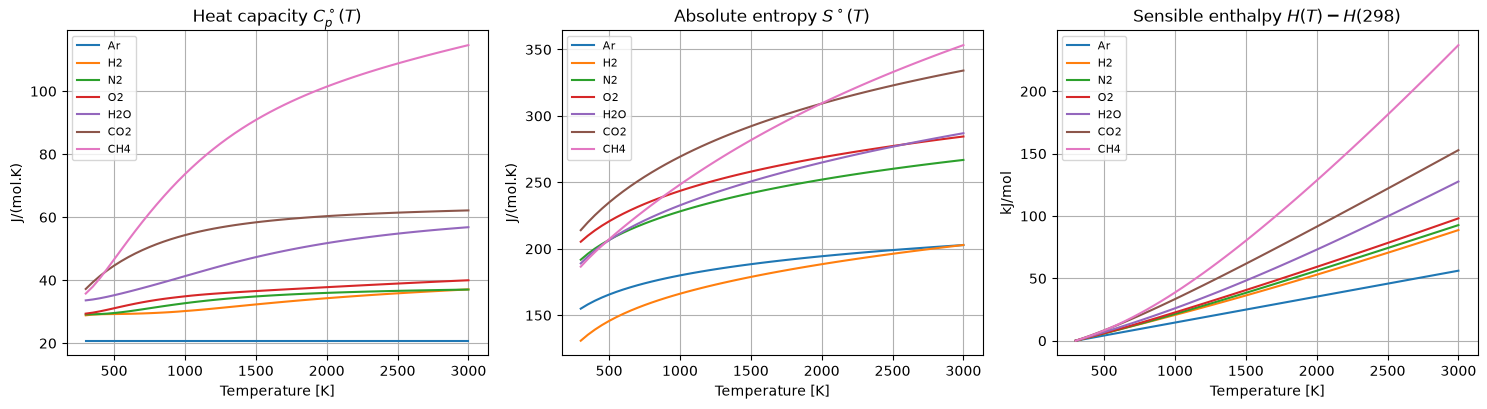

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
with ThermochemicalCalculator() as calc:
    h_ref = {n: calc.calculate_properties(calc.get_available_species(n, exact_match=True)[0].id, 298.15).h_relative
             for n in SPECIES}

for name in SPECIES:
    T, cp, s, h = data[name]
    axes[0].plot(T, cp, label=name)
    axes[1].plot(T, s, label=name)
    axes[2].plot(T, (h - h_ref[name]) / 1000.0, label=name)

axes[0].set_title(r"Heat capacity $C_p^\circ(T)$"); axes[0].set_ylabel("J/(mol.K)")
axes[1].set_title(r"Absolute entropy $S^\circ(T)$"); axes[1].set_ylabel("J/(mol.K)")
axes[2].set_title("Sensible enthalpy $H(T)-H(298)$"); axes[2].set_ylabel("kJ/mol")
for ax in axes:
    ax.set_xlabel("Temperature [K]"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Reading the physics: equipartition

The dimensionless heat capacity $C_p/R$ exposes molecular structure. By
equipartition, each fully active quadratic degree of freedom contributes
$\tfrac12 R$ to $C_v$, and for an ideal gas $C_p = C_v + R$:

* **Monatomic** (Ar): only 3 translational modes $\Rightarrow C_v=\tfrac32 R$,
  so $C_p=\tfrac52 R$ — flat at all temperatures.
* **Diatomic** (N₂, O₂, H₂): + 2 rotational modes $\Rightarrow C_p=\tfrac72 R$
  at moderate $T$, rising further as the vibrational mode switches on.
* **Polyatomic** (CO₂, H₂O, CH₄): more rotational and many vibrational modes,
  so $C_p/R$ is larger and climbs steeply.

The dashed lines mark the $\tfrac52$ and $\tfrac72$ plateaus.

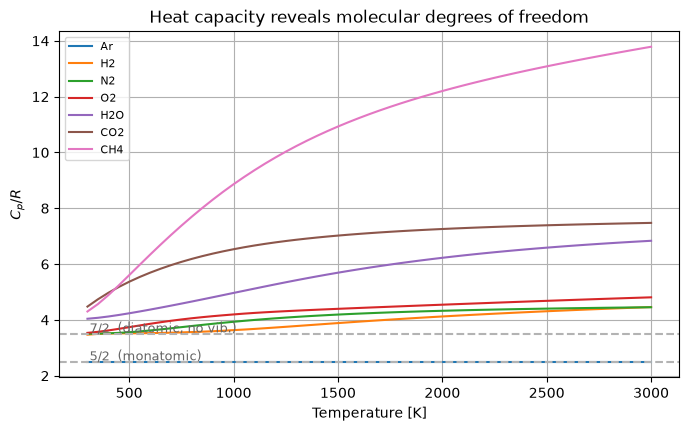

In [5]:
fig, ax = plt.subplots()
for name in SPECIES:
    T, cp, s, h = data[name]
    ax.plot(T, cp / R, label=name)
for level, txt in [(2.5, "5/2  (monatomic)"), (3.5, "7/2  (diatomic, no vib.)")]:
    ax.axhline(level, ls="--", color="0.7")
    ax.text(310, level + 0.05, txt, fontsize=9, color="0.4")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"$C_p / R$")
ax.set_title("Heat capacity reveals molecular degrees of freedom")
ax.legend(fontsize=8)
plt.show()

### New in 0.3.0: derivative of $C_p$ and the $C_p/C_v$ ratio

`pyglenn` 0.3.0 added three single-temperature helpers that are handy here:

* `dcp_dt(id, T)` — the analytical derivative $dC_p/dT$ (in
  J/(mol·K²)), evaluated directly from the polynomial;
* `gamma(id, T)` — the ideal-gas heat-capacity ratio
  $\gamma = C_p/C_v = C_p/(C_p - R)$;
* `h_sensible_to(id, T)` — the sensible enthalpy
  $H^\circ(T) - H^\circ(298.15)$ (alias of `calculate_enthalpy_change`).


In [6]:
Tgrid = np.linspace(300, 3000, 6)
with ThermochemicalCalculator() as calc:
    sid = calc.get_available_species("N2", exact_match=True)[0].id
    for T in Tgrid:
        print(f"T={T:6.1f} K  gamma={calc.gamma(sid, T):.4f}  "
              f"dcp_dt={calc.dcp_dt(sid, T):.4f} J/(mol.K^2)  "
              f"h_sensible={calc.h_sensible_to(sid, T)/1000:7.2f} kJ/mol")


T= 300.0 K  gamma=1.3995  dcp_dt=0.0005 J/(mol.K^2)  h_sensible=   0.05 kJ/mol
T= 840.0 K  gamma=1.3555  dcp_dt=0.0066 J/(mol.K^2)  h_sensible=  16.31 kJ/mol
T=1380.0 K  gamma=1.3182  dcp_dt=0.0036 J/(mol.K^2)  h_sensible=  34.25 kJ/mol
T=1920.0 K  gamma=1.3022  dcp_dt=0.0018 J/(mol.K^2)  h_sensible=  53.26 kJ/mol
T=2460.0 K  gamma=1.2942  dcp_dt=0.0010 J/(mol.K^2)  h_sensible=  72.83 kJ/mol
T=3000.0 K  gamma=1.2896  dcp_dt=0.0007 J/(mol.K^2)  h_sensible=  92.71 kJ/mol


## 4. A property table with pandas

Discrete tables are still handy for reports. Here is $C_p$ at a set of
temperatures for every species, sorted by the value at 2000 K to rank them by
how much energy they soak up when hot.

In [7]:
table_temps = [300, 600, 1000, 1500, 2000, 2500]
records = {}
with ThermochemicalCalculator() as calc:
    for name in SPECIES:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        records[name] = {f"{t} K": calc.calculate_properties(sid, t).cp
                         for t in table_temps}

cp_df = pd.DataFrame(records).T.sort_values("2000 K", ascending=False)
cp_df.index.name = "species"
print("Cp [J/(mol.K)]")
print(cp_df.to_string())

Cp [J/(mol.K)]
         300 K  600 K  1000 K  1500 K  2000 K  2500 K
species                                              
CH4     35.760 52.691  73.676  90.866 101.443 108.790
CO2     37.220 47.323  54.309  58.374  60.335  61.443
H2O     33.596 36.324  41.291  47.318  51.756  54.777
O2      29.388 32.090  34.883  36.553  37.784  38.933
N2      29.125 30.109  32.696  34.842  35.970  36.615
H2      28.849 29.318  30.206  32.305  34.276  35.832
Ar      20.786 20.786  20.786  20.786  20.786  20.786


## 5. Instantaneous vs. mean heat capacity

Two heat capacities appear in engineering calculations:

* the **instantaneous** $C_p(T) = \left(\partial H/\partial T\right)_p$;
* the **mean** $\overline{C_p}\big|_{T_1}^{T_2} = \dfrac{H(T_2)-H(T_1)}{T_2-T_1}$,
  which is what you actually multiply by $\Delta T$ to get an enthalpy change.

Using `calculate_enthalpy_change` for the numerator, we compare the two for
nitrogen. The mean (from 300 K) lags the instantaneous value because it
averages in the cooler, lower-$C_p$ region.

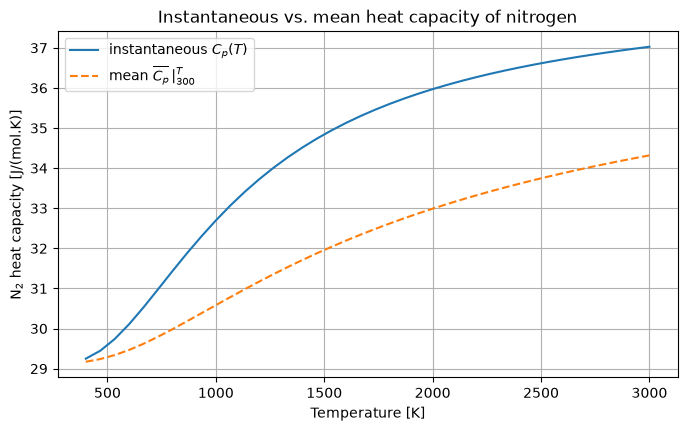

In [8]:
T2 = np.linspace(400, 3000, 40)
with ThermochemicalCalculator() as calc:
    n2 = calc.get_available_species("N2", exact_match=True)[0].id
    cp_inst = np.array([calc.calculate_properties(n2, t).cp for t in T2])
    cp_mean = np.array([calc.calculate_enthalpy_change(n2, 300.0, t) / (t - 300.0)
                        for t in T2])

fig, ax = plt.subplots()
ax.plot(T2, cp_inst, label=r"instantaneous $C_p(T)$")
ax.plot(T2, cp_mean, "--", label=r"mean $\overline{C_p}\,|_{300}^{T}$")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel("N$_2$ heat capacity [J/(mol.K)]")
ax.set_title("Instantaneous vs. mean heat capacity of nitrogen")
ax.legend()
plt.show()

## 6. Condensed phases have narrower ranges

Gas-phase fits typically cover 200–6000 K, but liquids and solids are only
valid over a small window. Requesting a temperature outside that window raises
a `TemperatureOutOfRangeError` — catch it with `try/except`. Liquid water is a
good example.

In [9]:
from pyglenn import TemperatureOutOfRangeError

with ThermochemicalCalculator() as calc:
    liq = calc.get_available_species("H2O(L)", exact_match=True)[0].id
    data_liq = calc.db.get_species_data(liq)
    ranges = [(iv.temp_min, iv.temp_max) for iv in data_liq.intervals]
    print("H2O(L) valid interval(s):", ranges)
    for T in [350.0, 2000.0]:
        try:
            p = calc.calculate_properties(liq, T)
            print(f"  T = {T:7.1f} K  ->  Cp = {p.cp:.2f} J/(mol.K)")
        except TemperatureOutOfRangeError:
            print(f"  T = {T:7.1f} K  ->  out of range")

H2O(L) valid interval(s): [(273.15, 373.15), (373.15, 600.0)]
  T =   350.0 K  ->  Cp = 75.53 J/(mol.K)
  T =  2000.0 K  ->  out of range


## Summary

- `calculate_properties_range` sweeps many temperatures in one call.
- The shape of $C_p/R$ directly reflects translational, rotational and
  vibrational degrees of freedom.
- Mean and instantaneous $C_p$ differ — use the mean (via
  `calculate_enthalpy_change`) for finite $\Delta T$.
- Always handle `None` for out-of-range temperatures, especially for condensed
  phases.

**Next:** notebook 04 extracts enthalpies of formation from these same
polynomials.